## Preface to the Linear Coherence Spectrum Filtering of the different datasets:

This scropt begins by computing the 2D power spectra in space of the instantaneous snapshots for the different datasets generated by the Princeton group. In this script we implement a 2D spectral analysis to get the spatial power spectra for different variables. This is a first step needed to ensure that the power spectra we are computing in 2D is correct. In essence we are aiming to recover a $k^{-1}$ and $k^{-5/3}$ power spectra scaling. Once this is working properly, we can use part of the analysis to compute the LCS that we need.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.io import FortranFile
import os

In [52]:
# Simulation Configuration Parameters:

#For the Heterogeneous cases (similar to thos of Fabien)
Nx = 256
Ny = 256
Nz = 256
Nz_SLayer = 128

#For the homogeneous case: (Abed has reused data from some other simulations)
#Nx = 200
#Ny = 200
#Nz = 200

zi = 1000
Lz = 2*zi
Lx = 2*np.pi*zi
Ly = 2*np.pi*zi
dz = Lz/Nz
dx = Lx/Nx
dy = Ly/Nx


#Noutputs = 256 #For the Het-1-800
#Noutputs = 240 #For the Homog
#Noutputs = 100 #For the Het-3-800
#Noutputs = 100 #For the Het-6-800
#Noutputs = 50 #For the Het-9-800
#Noutputs = 336 #For the Het-1-200
#Noutputs = 131 #For the Het-6-200
#Noutputs = 50 #For the Het-9-200
#Noutputs = 336 #For the Het-1-400
Noutputs = 53 #For the Het-9-400

#start_time = 802500 #For the Het-1-800
#start_time = 2500 #For the Het-3-800 case
#start_time = 435000 #For the Het-6-800 case
#start_time = 30000 #For the Het-9-800 case
#start_time = 202500 #For the Homog
#start_time = 2500 #For the Het-1-s200 case
#start_time = 15000 #For the Het-6-s200 case
#start_time = 30000 #For the Het-9-s200 case
#start_time = 2500 #For the Het-1-400 case
start_time = 30000 #For the Het-9-400 case

#output_stamps = 2500 #For the Homog
#output_stamps = 2500 #For the HET-1-s800
#output_stamps = 2500 #For the Het-3-800 case
#output_stamps = 15000 #For the Het-6-800 case
#output_stamps = 30000 #For the Het-9-800 case
#output_stamps = 2500 #For the Het-1-200 case
#output_stamps = 15000 #For the Het-6-200 case
#output_stamps = 30000 #For the Het-9-200 case
#output_stamps = 2500 #For the HET-1-s400
output_stamps = 30000 #For the HET-9-s400


collocated = 0 #0, False; 1, True; Het-1-800 is the only one for which this is 0, False.

#Path of the specific study case:
study_case_path = 'HET-9-s400'  #
#study_case_path = 'homogeneous_unstable'

path = '/uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/'+ study_case_path

#Path from where we read the post-processed information:
path_snap = path + '/snapshots/'

#Path for the long-term averaged statistics:
path_aver = path + '/avers/'


loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0802500.out


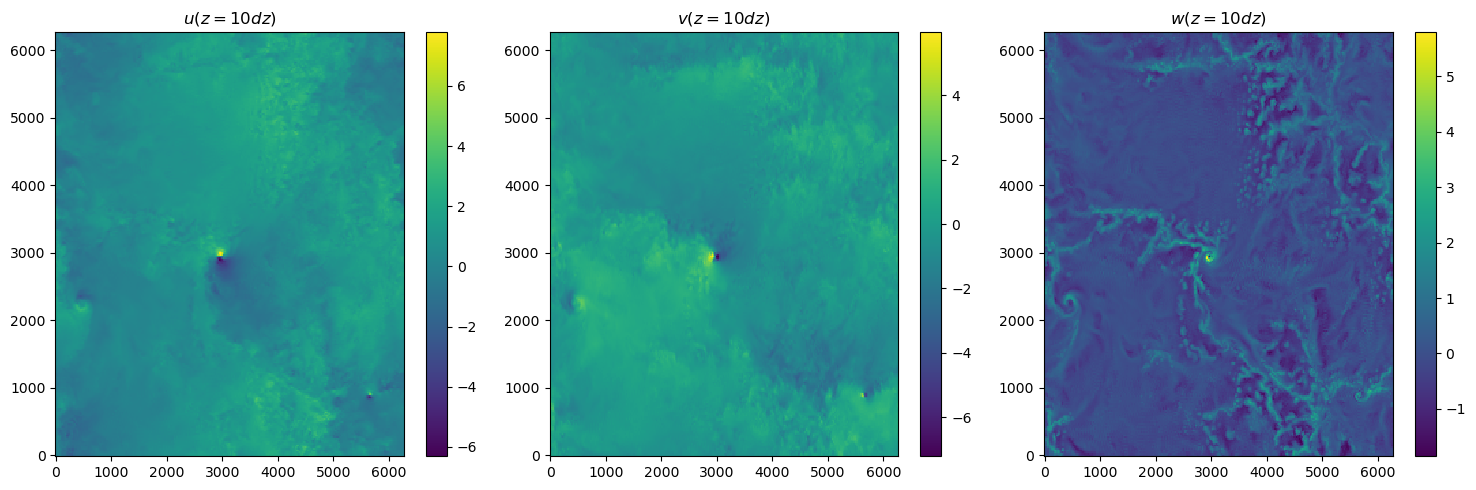

In [56]:
# Next we begin to read the snapshots of the velocity and temperature fields. 
# The snapshots are stored in Fortran binary files, which we will read using the FortranFile class from scipy.io.:

w_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')
v_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')
u_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')
T_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')

t_stamps = 1 #Number of snapshots to be used:
#t_stamps = Noutputs


for t in range(0,t_stamps):
    
    time_stamp = start_time + t*output_stamps

    if time_stamp < 10000:
        fname = path_snap+'scott_vel_sc000'+str(time_stamp)+'.out'
    elif(time_stamp >= 10000 and time_stamp < 100000):
        fname = path_snap+'scott_vel_sc00'+str(time_stamp)+'.out'
    elif(time_stamp >= 100000 and time_stamp < 1000000):
        fname = path_snap+'scott_vel_sc0'+str(time_stamp)+'.out'
    else:
        fname = path_snap+'scott_vel_sc'+str(time_stamp)+'.out'

    
    print(f'loaded snapshot = {fname}')
    f = FortranFile(fname, 'r')
    data = f.read_reals(dtype=np.float64)
    f.close()

    u = data[0:(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    v = data[(Nx+2)*Ny*(Nz+1):2*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    w = data[2*(Nx+2)*Ny*(Nz+1):3*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    T = data[3*(Nx+2)*Ny*(Nz+1):4*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')

    w_snap = w[:Nx, :Ny, :Nz]
    v_snap = v[:Nx, :Ny, :Nz]
    u_snap = u[:Nx, :Ny, :Nz]
    T_snap = T[:Nx, :Ny, :Nz]


#PLotting (u,v,w) snapshot at a fixed height (z = 10dz):
zref = 10 #Reference height for the snapshot (z = 10dz)

x_ax = np.arange(0,Nx)*dx
y_ax = np.arange(0,Ny)*dy

fig, axs = plt.subplots(nrows = 1, ncols = 3,figsize =(15,5))
im1 = axs[0].pcolormesh(x_ax,y_ax,np.transpose(u_snap[:,:,zref]))
im2 = axs[1].pcolormesh(x_ax,y_ax,np.transpose(v_snap[:,:,zref]))
im3 = axs[2].pcolormesh(x_ax,y_ax,np.transpose(w_snap[:,:,zref]))

fig.colorbar(im1, ax=axs[0])
fig.colorbar(im2, ax=axs[1])
fig.colorbar(im3, ax=axs[2])

axs[0].set_title(r'$u(z = 10dz)$')
axs[1].set_title(r'$v(z = 10dz)$')
axs[2].set_title(r'$w(z = 10dz)$')

plt.tight_layout()

In [58]:
#Compute the Power Spectral Density (PSD) of the velocity and temperature fields at a fixed height (z = 10dz):

var_prime = u_snap - np.mean(u_snap, axis=(0, 1))  # Example for u component; adjust as needed for v, w, T

#1. Compute the 2D FFT of the variable at the reference height (z = 10dz):
signal = np.squeeze(var_prime[:,:,zref])
fft_signal = np.fft.fft2(signal,s=(Nx,Ny),norm='forward') #Here, the nyquist frequency is at the center of the array.

#2. Shift the zero-frequency component to the center of the spectrum:
shifted_fft = np.fft.fftshift(fft_signal)
PSD = np.abs(shifted_fft*np.conj(shifted_fft))

# Compute the wavenumbers corresponding to the FFT frequencies in both x and y directions:    
kx = np.fft.fftfreq(signal.shape[0], d=dx) #This is the Wavenumber vector in the x-direction. We only need to keep the positive frequencies (first half), since the negative frequencies are redundant for real-valued signals.
ky = np.fft.fftfreq(signal.shape[1], d=dy) #This are in essence k = 1/lambda, where lambda is the wavelength. The units of kx and ky are 1/m. No 2pi on the numerator.

# Keep the PSD and frequency/wavelength grid the same size and ordering
shifted_kx = np.fft.fftshift(kx)
shifted_ky = np.fft.fftshift(ky)
kx2, ky2 = np.meshgrid(shifted_kx, shifted_ky, indexing='ij')
k_grid = np.sqrt(kx2**2 + ky2**2)

#Remove the zero-frequency component from the PSD and wavelength grid to avoid division by zero in subsequent calculations:
trim_PSD = PSD[1:,1:]
trim_k_grid = k_grid[1:,1:]

#3. Define the radial coordinate:
center_y, center_x = np.array(trim_PSD.shape) // 2
x, y = np.indices(trim_PSD.shape)
r = (np.sqrt((x - center_x)**2 + (y - center_y)**2))

# Sort the radial distances and corresponding correlation values
r_flat = r.ravel()
spectrum_flat = trim_PSD.ravel()
k_flat = trim_k_grid.ravel()

#4. Use a histogram-like method to bin the data
num_bins = int(Nx/2) -1
r_bins = np.linspace(0, int(Nx/2) -1, num_bins)
r_avg = np.zeros(num_bins - 1)
spectrum_radial = np.zeros(num_bins - 1)
k_radial = np.zeros(num_bins - 1)



for i in range(num_bins - 1):
        mask = (r_flat >= r_bins[i]) & (r_flat < r_bins[i+1])
        if np.any(mask):
            r_avg[i] = (np.mean(r_flat[mask]))
            spectrum_radial[i] = np.mean(spectrum_flat[mask])
            k_radial[i] = np.mean(k_flat[mask])
            

PSpectra = 2*spectrum_radial




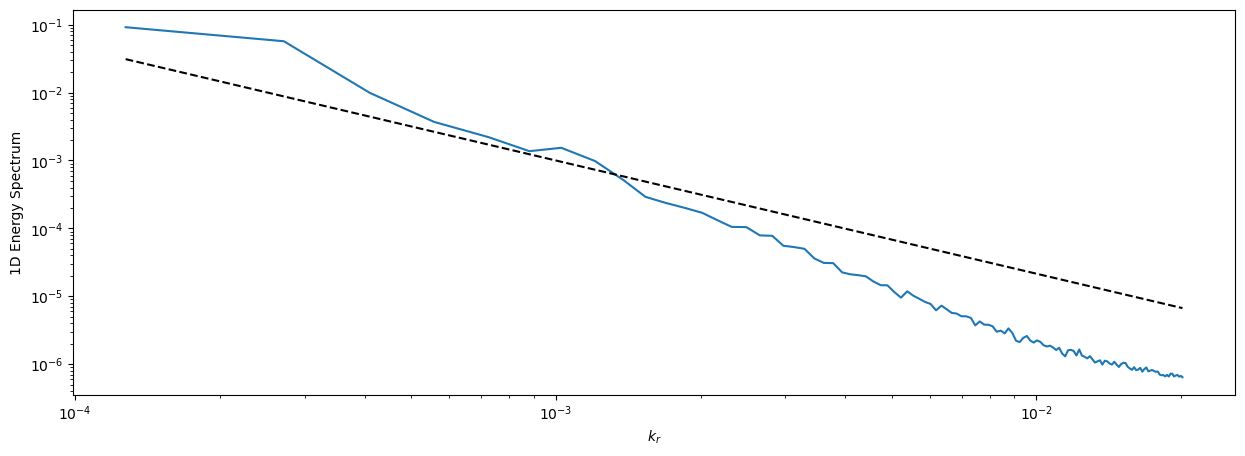

In [59]:
#Graphical representation of the corresponding 1D Power Spectra:

lambda_radial = 1/k_radial

fig, axs=plt.subplots(1,1,figsize=(15,5))
axs.loglog(k_radial,PSpectra)
axs.set_xlabel(r'$k_r$')
axs.set_ylabel(r'1D Energy Spectrum')

coef = 1e-8 #This is a coefficient that can be adjusted to fit the $k^{-5/3}$ line to the data. You can change this value to see how it affects the fit.
axs.loglog(k_radial,coef*k_radial**(-5/3),label=r'$k^{-5/3}$',linestyle='--',color='black')



At this time the code above computes the correct 2D Power spectra averaged using a radial approach with the corresponding appropriate wavelength/wavenumber axis. The next step is to include this code in a function, and then apply it at each snapshot. At the end average over all the snapshots. This should provide a smoothed power spectra for a given variable.

In [60]:
def RadialPowerSpectra(var_snap, zref, Nx, Ny, dx, dy):
    # This function computes the radial power spectra of a 2D field.
    # It takes no arguments and returns the radial wavenumber and the corresponding power spectrum.

    var_prime = var_snap - np.mean(var_snap, axis=(0, 1))  # Example for u component; adjust as needed for v, w, T

    # Compute the 2D FFT of the variable at the reference height (z = 10dz):
    signal = np.squeeze(var_prime[:,:,zref])
    fft_signal = np.fft.fft2(signal,s=(Nx,Ny),norm='forward') #Here, the nyquist frequency is at the center of the array.

    # Shift the zero-frequency component to the center of the spectrum:
    shifted_fft = np.fft.fftshift(fft_signal)
    PSD = np.abs(shifted_fft*np.conj(shifted_fft))

    # Compute the wavelengths corresponding to the FFT frequencies in both x and y directions:    
    kx = np.fft.fftfreq(signal.shape[0], d=dx) #This is the Wavenumber vector in the x-direction. We only need to keep the positive frequencies (first half), since the negative frequencies are redundant for real-valued signals.
    ky = np.fft.fftfreq(signal.shape[1], d=dy) #This is the Wavenumber vector in the y-direction. We only need to keep the positive frequencies, since the negative frequencies are redundant for real-valued signals.

    # Keep the PSD and frequency/wavelength grid the same size and ordering
    shifted_kx = np.fft.fftshift(kx)
    shifted_ky = np.fft.fftshift(ky)
    kx2, ky2 = np.meshgrid(shifted_kx, shifted_ky, indexing='ij')
    k_grid = np.sqrt(kx2**2 + ky2**2)

    #Remove the zero-frequency component from the PSD and wavelength grid to avoid division by zero in subsequent calculations:
    trim_PSD = PSD[1:,1:]
    trim_k_grid = k_grid[1:,1:]

    #Define the radial coordinate:
    center_y, center_x = np.array(trim_PSD.shape) // 2
    x, y = np.indices(trim_PSD.shape)
    r = (np.sqrt((x - center_x)**2 + (y - center_y)**2))

    #Sort the radial distances and corresponding correlation values
    r_flat = r.ravel()
    spectrum_flat = trim_PSD.ravel()
    k_flat = trim_k_grid.ravel()

    #Use a histogram-like method to bin the data
    num_bins = int(Nx/2) -1
    r_bins = np.linspace(0, int(Nx/2) -1, num_bins)
    r_avg = np.zeros(num_bins - 1)
    spectrum_radial = np.zeros(num_bins - 1)
    k_radial = np.zeros(num_bins - 1)

    for i in range(num_bins - 1):
            mask = (r_flat >= r_bins[i]) & (r_flat < r_bins[i+1])
            if np.any(mask):
                r_avg[i] = (np.mean(r_flat[mask]))
                spectrum_radial[i] = np.mean(spectrum_flat[mask])
                k_radial[i] = np.mean(k_flat[mask])
            

    PSpectra = 2*spectrum_radial
    
    return PSpectra, k_radial

In [61]:
#At this time we can call the function to compute the radial power spectra for the u, v, w, and T fields at the reference height (z = 10dz) 
#for a succession of snapshots. The results can be stored in a dictionary for further analysis or plotting.


w_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')
v_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')
u_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')
T_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')

t_stamps = 10 #Number of snapshots to be used:
#t_stamps = Noutputs


for t in range(0,t_stamps):
    
    time_stamp = start_time + t*output_stamps

    if time_stamp < 10000:
        fname = path_snap+'scott_vel_sc000'+str(time_stamp)+'.out'
    elif(time_stamp >= 10000 and time_stamp < 100000):
        fname = path_snap+'scott_vel_sc00'+str(time_stamp)+'.out'
    elif(time_stamp >= 100000 and time_stamp < 1000000):
        fname = path_snap+'scott_vel_sc0'+str(time_stamp)+'.out'
    else:
        fname = path_snap+'scott_vel_sc'+str(time_stamp)+'.out'

    
    print(f'loaded snapshot = {fname}')
    f = FortranFile(fname, 'r')
    data = f.read_reals(dtype=np.float64)
    f.close()

    u = data[0:(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    #v = data[(Nx+2)*Ny*(Nz+1):2*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    #w = data[2*(Nx+2)*Ny*(Nz+1):3*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    #T = data[3*(Nx+2)*Ny*(Nz+1):4*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')

    #w_snap = w[:Nx, :Ny, :Nz]
    #v_snap = v[:Nx, :Ny, :Nz]
    u_snap = u[:Nx, :Ny, :Nz]
    #T_snap = T[:Nx, :Ny, :Nz]
    
    zref = 10 #Reference height for the snapshot (z = 10dz)
    tmp_Spectra, k_radial = RadialPowerSpectra(u_snap, zref, Nx, Ny, dx, dy)
    
    Spectra = tmp_Spectra if t == 0 else np.vstack((Spectra, tmp_Spectra))

loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0802500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0805000.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0807500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0810000.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0812500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0815000.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0817500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0820000.out
loaded snapshot 

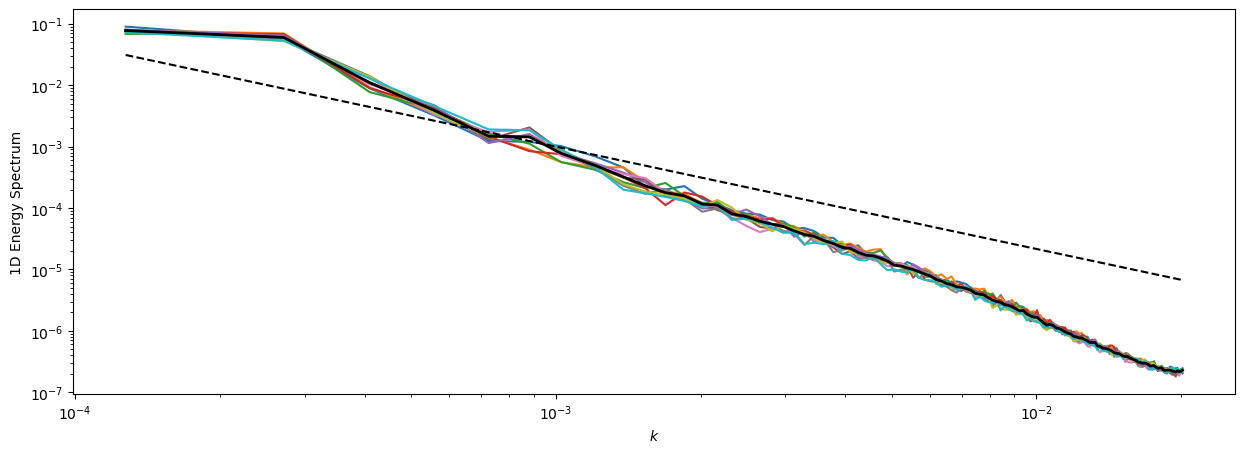

In [62]:
#Graphical representation of the corresponding 1D Power Spectra:

lambda_radial = 1/k_radial

fig, axs=plt.subplots(1,1,figsize=(15,5))

for t in range(0,t_stamps):
    axs.loglog(k_radial,Spectra[t,:],label=f'Snapshot {t+1}')

axs.loglog(k_radial,np.mean(Spectra,axis=0),label=f'Average over {t_stamps} snapshots',color='black',linewidth=2)
axs.set_xlabel(r'$k$')
axs.set_ylabel(r'1D Energy Spectrum')

coef = 1e-8 #This is a coefficient that can be adjusted to fit the $k^{-5/3}$ line to the data. You can change this value to see how it affects the fit.
axs.loglog(k_radial,coef*k_radial**(-5/3),label=r'$k^{-5/3}$',linestyle='--',color='black')


## LCS Script:
The function below computes the LCS for a succession of instantaneous snapshots. The LCS is computed using the power spectra and cross-power spectra computed spatially for each snapshot. The corresponding spectra are computed with information at two planes of different height. The corresponding FFTs are done in 2D, and then radially avergaed through bins to get 1D signals.

In [5]:
def LCS_terms(var_snap, z0, zref, Nx, Ny, dx, dy):
    # This function computes the radial power spectra of a 2D field.
    # It takes no arguments and returns the radial wavenumber and the corresponding power spectrum.

    var_prime = var_snap - np.mean(var_snap, axis=(0, 1))  # Example for u component; adjust as needed for v, w, T

    # Compute the 2D FFT of the variable at the reference height (z = 10dz):
    signal1 = np.squeeze(var_prime[:,:,z0])
    fft_signal1 = np.fft.fft2(signal1,s=(Nx,Ny),norm='forward') #Here, the nyquist frequency is at the center of the array.
    signal2 = np.squeeze(var_prime[:,:,zref])
    fft_signal2 = np.fft.fft2(signal2,s=(Nx,Ny),norm='forward') #Here, the nyquist frequency is at the center of the array.

    # Shift the zero-frequency component to the center of the spectrum:
    shifted_fft1 = np.fft.fftshift(fft_signal1)
    shifted_fft2 = np.fft.fftshift(fft_signal2)
    num = (np.abs(shifted_fft1*np.conj(shifted_fft2)))**2
    denom1 = (np.abs(shifted_fft1*np.conj(shifted_fft1)))**2
    denom2 = (np.abs(shifted_fft2*np.conj(shifted_fft2)))**2

    # Compute the wavelengths corresponding to the FFT frequencies in both x and y directions:    
    k_x = np.fft.fftfreq(signal1.shape[0], d=dx) #This is the Wavenumber vector in the x-direction. We only need to keep the positive frequencies (first half), since the negative frequencies are redundant for real-valued signals.
    k_y = np.fft.fftfreq(signal1.shape[1], d=dy) #This is the Wavenumber vector in the y-direction. We only need to keep the positive frequencies, since the negative frequencies are redundant for real-valued signals.

    # Keep the PSD and frequency/wavelength grid the same size and ordering
    shifted_k_x = np.fft.fftshift(k_x)
    shifted_k_y = np.fft.fftshift(k_y)
    waveLx, waveLy = np.meshgrid(shifted_k_x, shifted_k_y, indexing='ij')
    k_grid = np.sqrt(waveLx**2 + waveLy**2)

    #Remove the zero-frequency component from the PSD and wavelength grid to avoid division by zero in subsequent calculations:
    trim_num = num[1:,1:]
    trim_denom1 = denom1[1:,1:]
    trim_denom2 = denom2[1:,1:]
    trim_k = k_grid[1:,1:]
    
    #Define the radial coordinate:
    center_y, center_x = np.array(trim_num.shape) // 2
    x, y = np.indices(trim_num.shape)
    r = (np.sqrt((x - center_x)**2 + (y - center_y)**2))

    #Sort the radial distances and corresponding correlation values
    r_flat = r.ravel()
    num_flat = trim_num.ravel()
    denom1_flat = trim_denom1.ravel()
    denom2_flat = trim_denom2.ravel()   
    k_flat = trim_k.ravel()

    #Use a histogram-like method to bin the data
    num_bins = int(Nx/2) -1
    r_bins = np.linspace(0, int(Nx/2) -1, num_bins)
    r_avg = np.zeros(num_bins - 1)
    num_radial = np.zeros(num_bins - 1)
    denom1_radial = np.zeros(num_bins - 1)
    denom2_radial = np.zeros(num_bins - 1)  
    k_radial = np.zeros(num_bins - 1)

    for i in range(num_bins - 1):
            mask = (r_flat >= r_bins[i]) & (r_flat < r_bins[i+1])
            if np.any(mask):
                r_avg[i] = (np.mean(r_flat[mask]))
                num_radial[i] = np.mean(num_flat[mask])
                denom1_radial[i] = np.mean(denom1_flat[mask])
                denom2_radial[i] = np.mean(denom2_flat[mask])
                k_radial[i] = np.mean(k_flat[mask])
            

    
    return num_radial, denom1_radial, denom2_radial, k_radial

## Application Example of the LCS:

Below we test the LCS function. If one is interested to run it for different cases, or scenarios can just follow the approach used below as an application example.

In [64]:
#At this time we can call the function to compute the numerator and denominators for each snapshot to compute the corresponding LCS.

w_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')

t_stamps = 10 #Number of snapshots to be used:
#t_stamps = Noutputs


for t in range(0,t_stamps):
    
    time_stamp = start_time + t*output_stamps

    if time_stamp < 10000:
        fname = path_snap+'scott_vel_sc000'+str(time_stamp)+'.out'
    elif(time_stamp >= 10000 and time_stamp < 100000):
        fname = path_snap+'scott_vel_sc00'+str(time_stamp)+'.out'
    elif(time_stamp >= 100000 and time_stamp < 1000000):
        fname = path_snap+'scott_vel_sc0'+str(time_stamp)+'.out'
    else:
        fname = path_snap+'scott_vel_sc'+str(time_stamp)+'.out'

    
    print(f'loaded snapshot = {fname}')
    f = FortranFile(fname, 'r')
    data = f.read_reals(dtype=np.float64)
    f.close()

    #u = data[0:(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    #v = data[(Nx+2)*Ny*(Nz+1):2*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    w = data[2*(Nx+2)*Ny*(Nz+1):3*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
    #T = data[3*(Nx+2)*Ny*(Nz+1):4*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')

    w_snap = w[:Nx, :Ny, :Nz]
    #v_snap = v[:Nx, :Ny, :Nz]
    #u_snap = u[:Nx, :Ny, :Nz]
    #T_snap = T[:Nx, :Ny, :Nz]
    
    z0 = 3 #Lowest Reference height for the snapshot (z = 3dz)
    zref = 93 #Highest Reference height for the snapshot (z = 20dz)
    num_radial, denom1_radial, denom2_radial, k_radial = LCS_terms(w_snap, z0, zref, Nx, Ny, dx, dy)

    num = num_radial if t == 0 else np.vstack((num, num_radial))
    denom1 = denom1_radial if t == 0 else np.vstack((denom1, denom1_radial))
    denom2 = denom2_radial if t == 0 else np.vstack((denom2, denom2_radial))

LCS = num.mean(axis=0)/np.sqrt(denom1.mean(axis=0)*denom2.mean(axis=0))

loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0802500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0805000.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0807500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0810000.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0812500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0815000.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0817500.out
loaded snapshot = /uufs/chpc.utah.edu/common/home/calaf-group3/Princeton_Data/HET-1-s800/snapshots/scott_vel_sc0820000.out
loaded snapshot 

Text(0, 0.5, 'LCS')

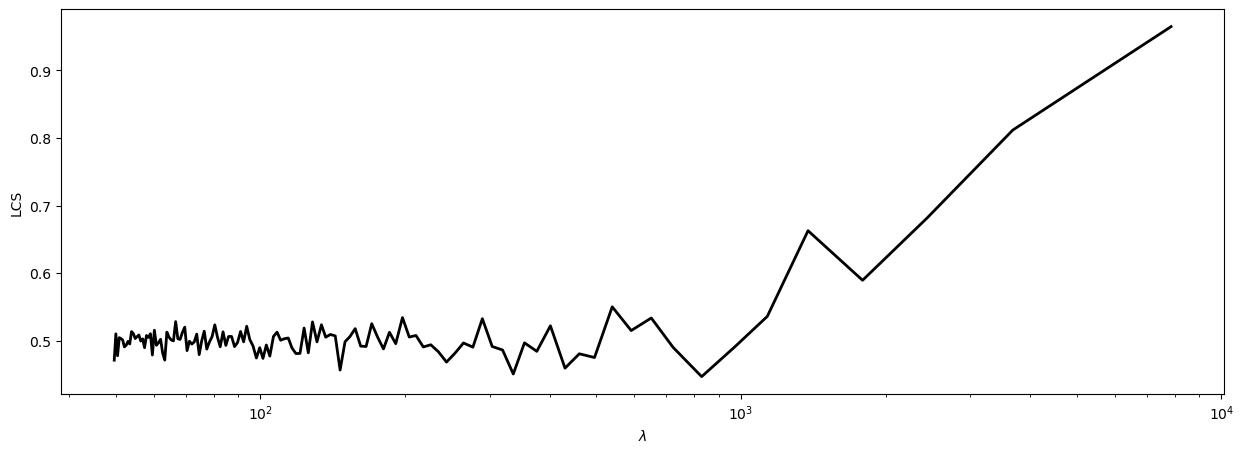

In [65]:
#Graphical representation of the corresponding LCS:

lambda_radial = 1/k_radial

fig, axs=plt.subplots(1,1,figsize=(15,5))

axs.semilogx(lambda_radial,LCS,label=f'LCS',color='black',linewidth=2)
axs.set_xlabel(r'$\lambda$')
axs.set_ylabel(r'LCS')



## LCS as a function of the reference height variation:

We can now extend the example above including a variation on the ref height, such that we get an LCS as a function of reference height variation.

In [53]:
z0 = 3
ztop = 100
step = 9
t_stamps = 20 #Number of snapshots to be used:
vec = np.arange(z0,ztop,step)
print(vec*dz)

LCS_z = np.zeros((vec.size,int(Nx/2)-2),dtype='float')

count = 0

for m in vec:
    
    print(f'Computing LCS for z = {m*dz} m, grid point = {m}')
    
    #At this time we can call the function to compute the numerator and denominators for each snapshot to compute the corresponding LCS.

    w_snap = np.zeros((Nx,Ny,Nz),dtype='float',order = 'F')

    #t_stamps = Noutputs


    for t in range(0,t_stamps):
    
        time_stamp = start_time + t*output_stamps

        if time_stamp < 10000:
            fname = path_snap+'scott_vel_sc000'+str(time_stamp)+'.out'
        elif(time_stamp >= 10000 and time_stamp < 100000):
            fname = path_snap+'scott_vel_sc00'+str(time_stamp)+'.out'
        elif(time_stamp >= 100000 and time_stamp < 1000000):
            fname = path_snap+'scott_vel_sc0'+str(time_stamp)+'.out'
        else:
            fname = path_snap+'scott_vel_sc'+str(time_stamp)+'.out'

    
        #print(f'loaded snapshot = {fname}')
        f = FortranFile(fname, 'r')
        data = f.read_reals(dtype=np.float64)
        f.close()

        #u = data[0:(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
        #v = data[(Nx+2)*Ny*(Nz+1):2*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
        w = data[2*(Nx+2)*Ny*(Nz+1):3*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')
        #T = data[3*(Nx+2)*Ny*(Nz+1):4*(Nx+2)*Ny*(Nz+1)].reshape((Nx+2, Ny, Nz+1), order='F')

        w_snap = w[:Nx, :Ny, :Nz]
        #v_snap = v[:Nx, :Ny, :Nz]
        #u_snap = u[:Nx, :Ny, :Nz]
        #T_snap = T[:Nx, :Ny, :Nz]
    
        z0 = 3 #Lowest Reference height for the snapshot (z = 3dz)
        zref = m #Reference height for the snapshot (z = mdz)
        num_radial, denom1_radial, denom2_radial, k_radial = LCS_terms(w_snap, z0, zref, Nx, Ny, dx, dy)

        num = num_radial if t == 0 else np.vstack((num, num_radial))
        denom1 = denom1_radial if t == 0 else np.vstack((denom1, denom1_radial))
        denom2 = denom2_radial if t == 0 else np.vstack((denom2, denom2_radial))

    LCS = num.mean(axis=0)/np.sqrt(denom1.mean(axis=0)*denom2.mean(axis=0))
    del num,denom1, denom2
    
    LCS_z[count,:] = LCS
    count += 1



[ 23.4375  93.75   164.0625 234.375  304.6875 375.     445.3125 515.625
 585.9375 656.25   726.5625]
Computing LCS for z = 23.4375 m, grid point = 3
Computing LCS for z = 93.75 m, grid point = 12
Computing LCS for z = 164.0625 m, grid point = 21
Computing LCS for z = 234.375 m, grid point = 30
Computing LCS for z = 304.6875 m, grid point = 39
Computing LCS for z = 375.0 m, grid point = 48
Computing LCS for z = 445.3125 m, grid point = 57
Computing LCS for z = 515.625 m, grid point = 66
Computing LCS for z = 585.9375 m, grid point = 75
Computing LCS for z = 656.25 m, grid point = 84
Computing LCS for z = 726.5625 m, grid point = 93


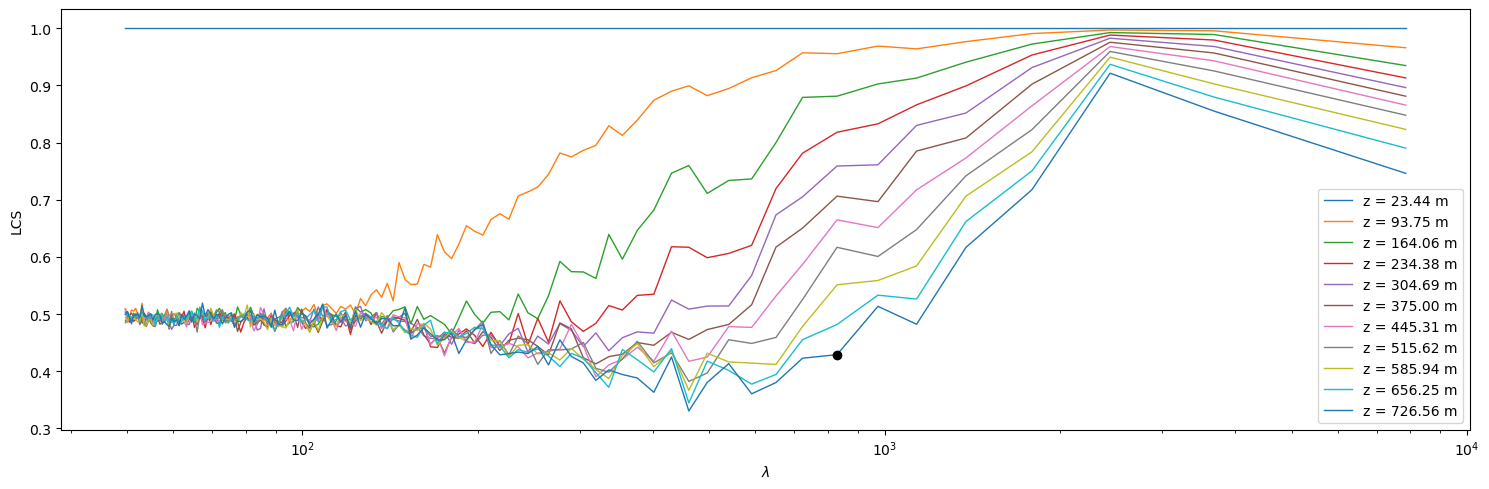

In [54]:
#Graphical representation of the corresponding LCS:

lambda_radial = 1/k_radial
xpoint = 7

fig, axs=plt.subplots(1,1,figsize=(15,5))
for n in range(0,vec.size):
    axs.semilogx(lambda_radial,LCS_z[n,:],label=f'z = {vec[n]*dz:.2f} m',linewidth=1)

#axs.vlines(lambda_radial[4], 0.5, 1, colors='black', linestyles='--', label=r'$\lambda_{max}$')
axs.plot(lambda_radial[xpoint], LCS_z[-1,xpoint], 'o', color='black', label=r'$\lambda_{max}$')
axs.set_xlabel(r'$\lambda$')
axs.set_ylabel(r'LCS')
plt.legend([f'z = {m*dz:.2f} m' for m in vec])

plt.axis('tight')
plt.tight_layout()

In [50]:
print(f'The critical length scale propagating through the BL is {lambda_radial[xpoint]} m')

The critical length scale propagating through the BL is 828.8021098375218 m


### Characteristic length scales for the different study cases:

Below we manually gather the data for the different study cases. Specifically we gather the approximated length scale/s that are common (appear correlated) through different heights. 

In [55]:
Convect_length = {'HET-1-s800': 1379.66,
                  'HET-1-s400': 1379.66,
                  'HET-1-s200': 1134.99,
                  'HET-6-s800': 974.35,
                  'HET-6-s200': 1134.99,
                  'HET-9-s800': 974.35,
                  'HET-9-s200': 828.80,
                  'HET-9-s400': 'Unclear'
                 }




### Comments on the Length-scales:

>For the HET-1 and HET-6 the length scale propagates through all heights.
>
>Interestingly for the HET-9, the length scale only propagates to z = 375m.
>
>The peak at HET-6-200 is much more clear than at HET-1-s200
>
> I NEED TO REDO THE ANALYSIS and SAVE THE Figures so it is easier to compare!!!!